Lab 8 — KNN: Raisin Classification
Name: Joonsuh Kim, William Roberts

Dataset: UCI Raisin Dataset
Source: https://archive.ics.uci.edu/dataset/850/raisin

Algorithm: K-Nearest Neighbors (KNN)

Question:
Can we predict a raisin's variety using its size and shape measurements?

Dataset description:
The dataset contains 900 raisins from two varieties: Besni and Kecimen.
There are 450 samples of each variety and seven numerical features.

Input features:
Area, MajorAxisLength, MinorAxisLength, Eccentricity,
ConvexArea, Extent, and Perimeter.

Target:
Class — Besni or Kecimen.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Read the Excel dataset already uploaded to Colab
df = pd.read_excel("Raisin_Dataset.xlsx")

# Display the first five rows
display(df.head())

print("Rows and columns:", df.shape)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count the samples in each variety
print("\nClass counts:")
print(df["Class"].value_counts())

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


Rows and columns: (900, 8)

Missing values:
Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64

Class counts:
Class
Kecimen    450
Besni      450
Name: count, dtype: int64


Data preparation

The dataset has 900 samples and no missing values.
Both varieties have 450 samples, so the classes are balanced.

I use the seven measurements as inputs and Class as the target.
The target is excluded from the inputs because it is the answer
the model must predict.

I divide the data into 80% training data and 20% test data.
The test data is kept separate to evaluate predictions on samples
that were not used for training.

In [ ]:
# X contains the measurements; y contains the correct variety
X = df.drop("Class", axis=1)
y = df["Class"]

# Keep the same class proportions in training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 720
Test samples: 180


Training samples: 720
Test samples: 180

Feature scaling

KNN compares samples using distances. The measurements have
different numerical scales, so a feature such as Area could
dominate the distance calculation.

I use StandardScaler to standardize the features. The scaling
parameters are learned only from the training data. The same
parameters are then applied to the test data.

In [ ]:
# Learn the mean and standard deviation from training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to the test data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


KNN classification

I use K=5, following the initial setting in the instructor's
pumpkin seed example. For each test raisin, the model finds the
five nearest training samples and predicts the variety with
the most votes.

K=5 is a starting setting. I have not compared different K
values, so I do not claim that it is the best choice.

In [ ]:
# Create a KNN classifier with five neighbors
model = KNeighborsClassifier(n_neighbors=5)

# Train using the scaled training measurements and known labels
model.fit(X_train_scaled, y_train)

# Predict the varieties of the test raisins
y_pred = model.predict(X_test_scaled)

print("Model training and prediction completed.")

Model training and prediction completed.


Evaluating the model

Accuracy shows the percentage of test samples classified
correctly. The classification report shows performance for
each variety.

The confusion matrix compares actual and predicted varieties.
Rows show the actual labels, and columns show the predicted
labels. Diagonal cells are correct predictions, while the
other cells are mistakes.

Test accuracy: 86.11%
Correct predictions: 155 out of 180

Classification report:
              precision    recall  f1-score   support

       Besni       0.93      0.78      0.85        90
     Kecimen       0.81      0.94      0.87        90

    accuracy                           0.86       180
   macro avg       0.87      0.86      0.86       180
weighted avg       0.87      0.86      0.86       180



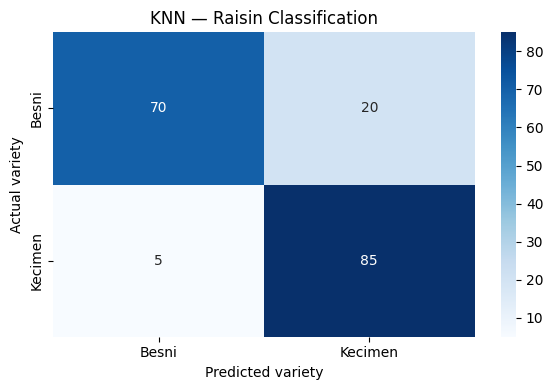

In [ ]:
# Calculate overall test accuracy
accuracy = accuracy_score(y_test, y_pred)
correct = (y_test.to_numpy() == y_pred).sum()

print(f"Test accuracy: {accuracy:.2%}")
print(f"Correct predictions: {correct} out of {len(y_test)}")

# Show results for each variety
print("\nClassification report:")
print(classification_report(y_test, y_pred))

# Create the confusion matrix in a consistent label order
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted variety")
plt.ylabel("Actual variety")
plt.title("KNN — Raisin Classification")
plt.tight_layout()
plt.show()

Test accuracy: 86.11%
Correct predictions: 155 out of 180

Summary

I used KNN to predict whether a raisin was Besni or Kecimen
using seven size and shape measurements. The dataset contained
900 samples and had no missing values.

I used 720 samples for training and 180 for testing. I
standardized the measurements using the training data and
applied the same scaling to the test data. The model used
five nearest neighbors.

The model correctly classified 155 of the 180 test raisins,
giving an accuracy of 86.1%. It correctly identified 70 of
the 90 Besni raisins and 85 of the 90 Kecimen raisins.
Besni raisins were more often confused with Kecimen than
the reverse.

These results suggest that size and shape measurements can
help sort the two raisin varieties. However, the model made
25 mistakes, so these measurements did not separate the
varieties perfectly. The result is based on one train-test
split, and K=5 was not compared with other K values.